<img src="http://imgur.com/1ZcRyrc.png" style="float: left; margin: 20px; height: 55px">

## Regularization and Optimization for Neural Networks

_Authors:_ Matt Brems, Tim Book, Justin Pounders


### Learning Objectives

By the end of the lesson, students should be able to:
- Explain how L1/L2, dropout, and early stopping regularization work and implement these methods in Keras
- Implement methods for speeding up learning

In [1]:
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense

import pandas as pd

## Load the data

In [2]:
data = pd.read_csv('../data/cell_phone_churn.csv')
data.head()

,state,account_length,area_code,intl_plan,vmail_plan,vmail_message,day_mins,day_calls,day_charge,eve_mins,eve_calls,eve_charge,night_mins,night_calls,night_charge,intl_mins,intl_calls,intl_charge,custserv_calls,churn
0,KS,128,415,no,yes,25,265.1,110,45.07,197.4,99,16.78,244.7,91,11.01,10.0,3,2.70,1,False
1,OH,107,415,no,yes,26,161.6,123,27.47,195.5,103,16.62,254.4,103,11.45,13.7,3,3.70,1,False
2,NJ,137,415,no,no,0,243.4,114,41.38,121.2,110,10.30,162.6,104,7.32,12.2,5,3.29,0,False
3,OH,84,408,yes,no,0,299.4,71,50.90,61.9,88,5.26,196.9,89,8.86,6.6,7,1.78,2,False
4,OK,75,415,yes,no,0,166.7,113,28.34,148.3,122,12.61,186.9,121,8.41,10.1,3,2.73,3,False


In [3]:
data = data.drop('state', axis=1)

# Many ways to binarize:
data['intl_plan'] = data['intl_plan'].map(lambda x: 1 if x=='yes' else 0)
data['vmail_plan'] = data['vmail_plan'].map(lambda x: 1 if x=='yes' else 0)

# data['intl_plan'] = data['intl_plan'].map({'yes': 1, 'no': 0})
# data['intl_plan'] = (data['intl_plan'] == 'yes').astype('int')
# data['intl_plan'] = (data['intl_plan'] == 'yes') * 1

In [4]:
X = data.drop('churn', axis=1)
y = data['churn'].astype('int')

X_train, X_test, y_train, y_test = train_test_split(X, y)

sc = StandardScaler()
X_train = sc.fit_transform(X_train)
X_test = sc.transform(X_test)

In [5]:
1 - y.mean()

0.8550855085508551

## Build a simple neural net to model churn

Let's build this:

- a dense network,
- one input layer,
- one hidden layer 
  - slightly smaller than input layer
  - ReLU activation
- single node output (for binary classification)
  - sigmoid activation
  
> **Fun fact**: If we dropped the hidden layer, this model would just be logistic regression!  Can you prove that to yourself?

In [6]:
n_input = X_train.shape[1]

In [7]:
n_input

18

In [8]:
model = Sequential()
model.add(Dense(18, input_dim=n_input, activation='relu'))
model.add(Dense(1, activation='sigmoid'))

In [9]:
model.compile(loss='binary_crossentropy', optimizer='adam', metrics=['acc'])

In [10]:
history = model.fit(
    X_train,
    y_train,
    validation_data=(X_test, y_test),
    epochs=100,
    batch_size=None,
    verbose=2
)

Train on 2499 samples, validate on 834 samples
Epoch 1/100
2499/2499 - 1s - loss: 0.5756 - acc: 0.7295 - val_loss: 0.4817 - val_acc: 0.8273
Epoch 2/100
2499/2499 - 0s - loss: 0.4253 - acc: 0.8563 - val_loss: 0.4128 - val_acc: 0.8429
Epoch 3/100
2499/2499 - 0s - loss: 0.3778 - acc: 0.8623 - val_loss: 0.3833 - val_acc: 0.8453
Epoch 4/100
2499/2499 - 0s - loss: 0.3551 - acc: 0.8647 - val_loss: 0.3653 - val_acc: 0.8477
Epoch 5/100
2499/2499 - 0s - loss: 0.3398 - acc: 0.8691 - val_loss: 0.3508 - val_acc: 0.8573
Epoch 6/100
2499/2499 - 0s - loss: 0.3278 - acc: 0.8727 - val_loss: 0.3398 - val_acc: 0.8573
Epoch 7/100
2499/2499 - 0s - loss: 0.3178 - acc: 0.8764 - val_loss: 0.3300 - val_acc: 0.8621
Epoch 8/100
2499/2499 - 0s - loss: 0.3087 - acc: 0.8816 - val_loss: 0.3206 - val_acc: 0.8621
Epoch 9/100
2499/2499 - 0s - loss: 0.3003 - acc: 0.8872 - val_loss: 0.3119 - val_acc: 0.8657
Epoch 10/100
2499/2499 - 0s - loss: 0.2926 - acc: 0.8888 - val_loss: 0.3059 - val_acc: 0.8657
Epoch 11/100
2499/2499

Epoch 88/100
2499/2499 - 1s - loss: 0.1880 - acc: 0.9416 - val_loss: 0.2195 - val_acc: 0.9137
Epoch 89/100
2499/2499 - 0s - loss: 0.1876 - acc: 0.9432 - val_loss: 0.2186 - val_acc: 0.9161
Epoch 90/100
2499/2499 - 0s - loss: 0.1871 - acc: 0.9416 - val_loss: 0.2184 - val_acc: 0.9137
Epoch 91/100
2499/2499 - 0s - loss: 0.1865 - acc: 0.9424 - val_loss: 0.2201 - val_acc: 0.9125
Epoch 92/100
2499/2499 - 0s - loss: 0.1859 - acc: 0.9432 - val_loss: 0.2207 - val_acc: 0.9113
Epoch 93/100
2499/2499 - 0s - loss: 0.1858 - acc: 0.9432 - val_loss: 0.2190 - val_acc: 0.9137
Epoch 94/100
2499/2499 - 0s - loss: 0.1858 - acc: 0.9432 - val_loss: 0.2190 - val_acc: 0.9113
Epoch 95/100
2499/2499 - 0s - loss: 0.1848 - acc: 0.9444 - val_loss: 0.2188 - val_acc: 0.9161
Epoch 96/100
2499/2499 - 0s - loss: 0.1840 - acc: 0.9424 - val_loss: 0.2189 - val_acc: 0.9125
Epoch 97/100
2499/2499 - 0s - loss: 0.1840 - acc: 0.9448 - val_loss: 0.2181 - val_acc: 0.9173
Epoch 98/100
2499/2499 - 0s - loss: 0.1839 - acc: 0.9428 - v

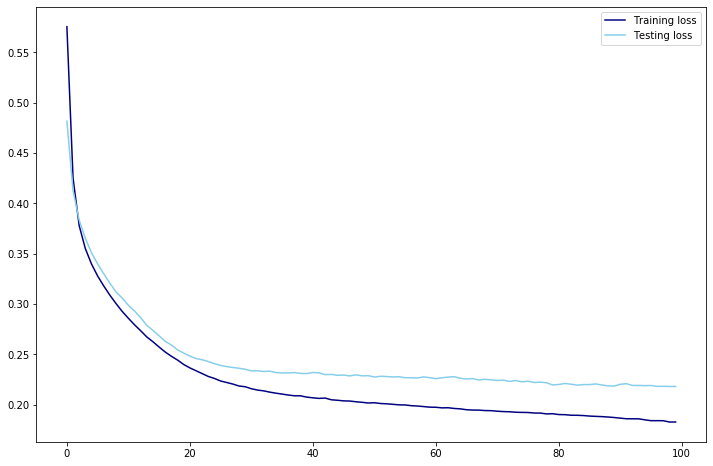

In [11]:
train_loss = history.history['loss']
test_loss = history.history['val_loss']
plt.figure(figsize=(12, 8))
plt.plot(train_loss, label='Training loss', color='navy')
plt.plot(test_loss, label='Testing loss', color='skyblue')
plt.legend();

In [12]:
history.history['acc'][-1], history.history['val_acc'][-1]

(0.9431773, 0.91007197)

![](../assets/overkill.jpg)

<a id='l1'></a>
## Regularization Method 1: $\mathcal{l}_1$ and $\mathcal{l}_2$
---
Just as we did with linear models, we can use $\mathcal{l}_1$ (LASSO) and $\mathcal{l}_2$ (Ridge) regularization on our neural networks.

Recall from our notation yesterday:

* $J(\theta) = L(\mathbf{y}, \hat{\mathbf{y}})$ is the value of the loss function with respect to...
* $\theta$, the list of _all_ model coefficients (all weights and biases).

We regularize our neural networks by adding a penalty term to our loss function:

$$ \text{minimize } J(\theta) + \lambda \|\theta\|_2^2 $$

This has the effect of penalizing our parameters $\theta$ by shrinking them, hence bartering in the bias-variance tradeoff by (hopefully) reducing variance by adding bias. Although it is rarely done, **Keras actually gives us the opportunity to penalize the weights at different layers by different amounts.**

## Which to pick: $\mathcal{l}_1$ or $\mathcal{l}_2$?
Recall the key difference: $\mathcal{l}_1$ penalties perform _selection_. That is, they often zero out parameters when they're small enough. While this sounds appealing, $\mathcal{l}_2$ is used almost exclusively. It's done so often, that deep learning practitions give it a special name: **weight decay**.

In [13]:
from tensorflow.keras import regularizers

model_l2 = Sequential()

n_input = X_train.shape[1]

model_l2.add(Dense(
    18,
    input_dim=n_input,
    activation='relu',
    kernel_regularizer=regularizers.l2(0.01)
))
model_l2.add(Dense(
    1,
    activation='sigmoid',
    kernel_regularizer=regularizers.l2(0.01)
))

model_l2.compile(
    loss='binary_crossentropy',
    optimizer='adam',
    metrics=['acc']
)

history_l2 = model_l2.fit(
    X_train,
    y_train,
    validation_data=(X_test, y_test),
    epochs=100,
    batch_size=None
)

Train on 2499 samples, validate on 834 samples
Epoch 1/100
2499/2499 [==============================] - 1s 358us/sample - loss: 0.6631 - acc: 0.8191 - val_loss: 0.6104 - val_acc: 0.8357
Epoch 2/100
2499/2499 [==============================] - 0s 157us/sample - loss: 0.5433 - acc: 0.8615 - val_loss: 0.5386 - val_acc: 0.8453
Epoch 3/100
2499/2499 [==============================] - 0s 132us/sample - loss: 0.4857 - acc: 0.8647 - val_loss: 0.4935 - val_acc: 0.8465
Epoch 4/100
2499/2499 [==============================] - 0s 131us/sample - loss: 0.4490 - acc: 0.8663 - val_loss: 0.4622 - val_acc: 0.8465
Epoch 5/100
2499/2499 [==============================] - 0s 193us/sample - loss: 0.4232 - acc: 0.8675 - val_loss: 0.4375 - val_acc: 0.8489
Epoch 6/100
2499/2499 [==============================] - 0s 155us/sample - loss: 0.4040 - acc: 0.8695 - val_loss: 0.4193 - val_acc: 0.8489
Epoch 7/100
2499/2499 [==============================] - 0s 150us/sample - loss: 0.3885 - acc: 0.8715 - val_loss: 0.405

2499/2499 [==============================] - 0s 148us/sample - loss: 0.3072 - acc: 0.9104 - val_loss: 0.3238 - val_acc: 0.8861
Epoch 60/100
2499/2499 [==============================] - 0s 126us/sample - loss: 0.3073 - acc: 0.9092 - val_loss: 0.3235 - val_acc: 0.8861
Epoch 61/100
2499/2499 [==============================] - 0s 123us/sample - loss: 0.3075 - acc: 0.9064 - val_loss: 0.3236 - val_acc: 0.8861
Epoch 62/100
2499/2499 [==============================] - 0s 131us/sample - loss: 0.3072 - acc: 0.9104 - val_loss: 0.3229 - val_acc: 0.8897
Epoch 63/100
2499/2499 [==============================] - 0s 135us/sample - loss: 0.3073 - acc: 0.9092 - val_loss: 0.3237 - val_acc: 0.8849
Epoch 64/100
2499/2499 [==============================] - 0s 129us/sample - loss: 0.3072 - acc: 0.9088 - val_loss: 0.3222 - val_acc: 0.8861
Epoch 65/100
2499/2499 [==============================] - 0s 178us/sample - loss: 0.3069 - acc: 0.9096 - val_loss: 0.3228 - val_acc: 0.8837
Epoch 66/100
2499/2499 [=========

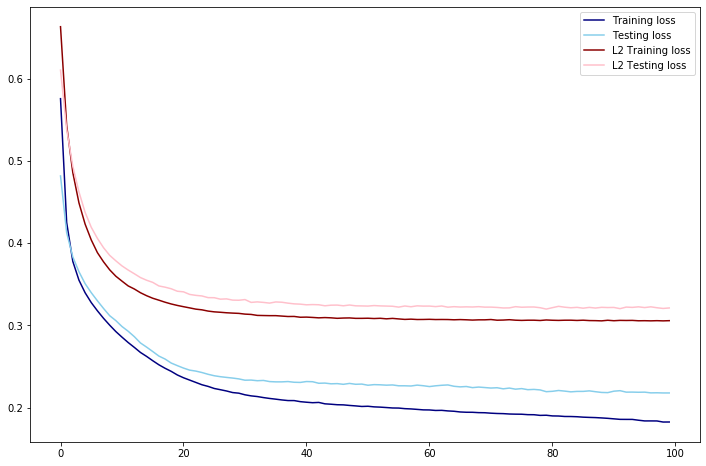

In [14]:
train_loss_l2 = history_l2.history['loss']
test_loss_l2 = history_l2.history['val_loss']
plt.figure(figsize=(12, 8))
plt.plot(train_loss, label='Training loss', color='navy')
plt.plot(test_loss, label='Testing loss', color='skyblue')
plt.plot(train_loss_l2, label='L2 Training loss', color='darkred')
plt.plot(test_loss_l2, label='L2 Testing loss', color='pink')
plt.legend();

In [15]:
history_l2.history['acc'][-1], history_l2.history['val_acc'][-1]

(0.91036415, 0.88968825)

## Keras Resources
- [Keras Regularization Documentation](https://keras.io/regularizers/)
- [Kernel vs. Activity Regularizers](https://github.com/keras-team/keras/issues/3236)

## Tensorflow Resources
- [Implementation in Tensorflow](https://www.tensorflow.org/versions/r0.12/api_docs/python/contrib.layers/regularizers)
- [Example in Tensorflow](http://www.ritchieng.com/machine-learning/deep-learning/tensorflow/regularization/)

<a id='dropout'></a>
## Regularization Method 2: Dropout
---
There's another method of regularizing our terms that is specifically designed for neural networks, called **dropout regularization.**

Let's say we've constructed a neural network. We've decided on the number of layers we want and the number of nodes in each layer. (We might say that we've decided on the **topology** or **structure** of our network.)

![](../assets/original_nn.jpeg)

However, a densely connected network like this will almost certainly overfit. Our network is learning a parameter for every single connection.

> We can overcome this by using **dropout regularization**. 

In dropout regularization, we randomly **drop** units (nodes) in our neural network ***during our training phase only***. We assign a probability of each node disappearing. Then, we essentially perform a coinflip for every node to turn that node "on" or "off."

Let's go through an example to illustrate this: For simplicity, we'll say we've assigned a 0.5 probability of keeping to every node in the network above. Then, for every node, we flip a coin, and if the coin lands on heads, the node remains, if it lands on tails, the node disappears. After we've done this for every node, we're left with a new network that looks something like this:

![](./assets/after_dropout.jpeg)

<!--
Image sources: https://pgaleone.eu/deep-learning/regularization/2017/01/10/anaysis-of-dropout/
Also, it seems, this site: http://cs231n.github.io/neural-networks-2/
-->

Let's explicitly lay out the general workflow you would follow:

1. Specify the **topology** of your neural network.
2. Initialize your weights and biases.
3. Specify the "keeping probabilities" for every node. (Generally, we'll assign the same probability to all nodes in each layer and usually the same probability to all hidden layers.)
4. Perform a "coin flip" for each node and drop out the chosen nodes.
5. Run through one epoch of training.
6. Repeat steps 4 and 5 for each epoch of training.

**Check:** If I drop out a node during one of my epochs, does it disappear from my final network?

#### So, what does this do?
<!-- <br/> -->
The intuition behind dropout is that, since each node has a probability of disappearing at any time, the neural network is disincentivized from allocating too much power to any one weight. It has a similar effect as imposing an L2 penalty: the magnitude of our weights shrinks.

**Check:** What might be some potential problems with doing this?

<!--
expected values of nodes changes; induces bias
-->

#### Inverted Dropout

In order to avoid any issues with the expected values of our nodes changing, we adjust our results accordingly by a method called **inverted dropout**.

If we have a hidden layer with 100 nodes and each node has a 80% probability of being "staying turned on," we only have 80% of those inputs to our node. As a result, we expect that the combined input to our node $z = b_0 + \sum_{i=1}^pw_ix_i$ will be off by about 20%. (Those interested in probability and research might note that the Binomial distribution is a very convenient model for neural networks and dropout.)

When using inverted dropout, we adjust $z$ by the "keeping probability."

$$
\begin{eqnarray*}
z_{original} &=& b_0 + \sum_{i=1}^pw_ix_i \\
\Rightarrow z_{dropout} &=& b_0 + \sum_{i\in\{included\_nodes\}}w_ix_i \\
\Rightarrow z_{inverted\_dropout} &:=& z_{dropout} / 0.8 \\
\end{eqnarray*}
$$

#### Test time:

So we've now run through every epoch of our training phase and we're ready to apply our neural network to our validation or testing data. Are we going to apply dropout to this data as well?

**NO.**

#### Best practices:

- Don't set any keeping probabilities for layers you where you don't want to drop any nodes. (What might be examples of these layers?)
<!--
Input and output layers
-->
- You'll generally want to specify a single keeping probability and all the layers on which you want to apply dropout, instead of specifying different keeping probabilities for each layer.

In [16]:
from tensorflow.keras.layers import Dropout

model_dropout = Sequential()

n_input = X_train.shape[1]
n_hidden = n_input

model_dropout.add(Dense(n_hidden, input_dim=n_input, activation='relu'))
model_dropout.add(Dropout(0.5)) # refers to nodes in the first hidden layer
model_dropout.add(Dense(1, activation='sigmoid'))

model_dropout.compile(loss='binary_crossentropy', optimizer='adam', metrics=['acc'])

history_dropout = model_dropout.fit(
    X_train,
    y_train,
    validation_data=(X_test, y_test), 
    epochs=100,
    batch_size=None
)

Train on 2499 samples, validate on 834 samples
Epoch 1/100
2499/2499 [==============================] - 1s 383us/sample - loss: 0.7330 - acc: 0.5770 - val_loss: 0.5478 - val_acc: 0.7890
Epoch 2/100
2499/2499 [==============================] - 0s 141us/sample - loss: 0.5580 - acc: 0.7295 - val_loss: 0.4586 - val_acc: 0.8429
Epoch 3/100
2499/2499 [==============================] - 0s 138us/sample - loss: 0.4978 - acc: 0.7915 - val_loss: 0.4207 - val_acc: 0.8441
Epoch 4/100
2499/2499 [==============================] - 0s 160us/sample - loss: 0.4492 - acc: 0.8371 - val_loss: 0.3998 - val_acc: 0.8465
Epoch 5/100
2499/2499 [==============================] - 0s 136us/sample - loss: 0.4220 - acc: 0.8487 - val_loss: 0.3868 - val_acc: 0.8453
Epoch 6/100
2499/2499 [==============================] - 0s 137us/sample - loss: 0.4165 - acc: 0.8511 - val_loss: 0.3741 - val_acc: 0.8441
Epoch 7/100
2499/2499 [==============================] - 0s 158us/sample - loss: 0.3889 - acc: 0.8567 - val_loss: 0.365

2499/2499 [==============================] - 0s 167us/sample - loss: 0.2521 - acc: 0.9100 - val_loss: 0.2404 - val_acc: 0.8993
Epoch 60/100
2499/2499 [==============================] - 0s 149us/sample - loss: 0.2559 - acc: 0.9144 - val_loss: 0.2393 - val_acc: 0.9029
Epoch 61/100
2499/2499 [==============================] - 0s 148us/sample - loss: 0.2525 - acc: 0.9108 - val_loss: 0.2370 - val_acc: 0.9041
Epoch 62/100
2499/2499 [==============================] - 0s 123us/sample - loss: 0.2482 - acc: 0.9176 - val_loss: 0.2359 - val_acc: 0.9029
Epoch 63/100
2499/2499 [==============================] - 0s 155us/sample - loss: 0.2565 - acc: 0.9096 - val_loss: 0.2376 - val_acc: 0.9005
Epoch 64/100
2499/2499 [==============================] - 0s 138us/sample - loss: 0.2564 - acc: 0.9136 - val_loss: 0.2363 - val_acc: 0.9029
Epoch 65/100
2499/2499 [==============================] - 0s 154us/sample - loss: 0.2541 - acc: 0.9132 - val_loss: 0.2365 - val_acc: 0.9017
Epoch 66/100
2499/2499 [=========

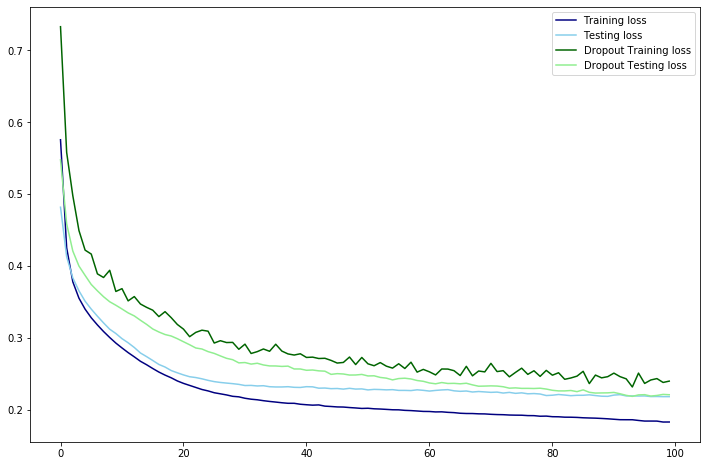

In [17]:
train_loss_dropout = history_dropout.history['loss']
test_loss_dropout = history_dropout.history['val_loss']
plt.figure(figsize=(12, 8))
plt.plot(train_loss, label='Training loss', color='navy')
plt.plot(test_loss, label='Testing loss', color='skyblue')
plt.plot(train_loss_dropout, label='Dropout Training loss', color='darkgreen')
plt.plot(test_loss_dropout, label='Dropout Testing loss', color='lightgreen')
plt.legend();

In [18]:
history_dropout.history['acc'][-1], history_dropout.history['val_acc'][-1]

(0.917567, 0.911271)

## Keras Resources
- [Keras Dropout Documentation](https://keras.io/layers/core/#dropout)

## Tensorflow Resources
- [Tensorflow documentation](https://www.tensorflow.org/api_docs/python/tf/nn/dropout)
- [List of examples in Tensorflow](https://programtalk.com/python-examples/tensorflow.nn.dropout/)

<a id='stopping'></a>
## Regularization Method 3: Early Stopping
---
The third method of regularization that we'll discuss today is called early stopping.
</br>
If we run though all our epochs of training and plot both our training and validation error, we'll typically see something like this:

![](../assets/train-val-error-reduced.png)
*source: [Prechelt, 1997](http://page.mi.fu-berlin.de/prechelt/Biblio/stop_tricks1997.pdf) *

**Check:** What is happening in this plot?

Early stopping does exactly what its name implies: it stop the training process early. Instead of continuing training through every epoch, once the validation error begins to increase, our algorithm stops because it has (in theory) found the minimum for the validation loss.

This might seem like a simple and robust solution to overfitting, but it can run into problems.

![](../assets/validation-error-real.png)

There is debate over how often this problem occurs. You can generally plot both the training and validation loss, see if you're getting multiple optima. If you are, there are multiple suggested techniques to combat this problem in the [paper reference above](http://page.mi.fu-berlin.de/prechelt/Biblio/stop_tricks1997.pdf).

In [19]:
from tensorflow.keras.callbacks import EarlyStopping

model_es = Sequential()

n_input = X_train.shape[1]

model_es.add(Dense(n_hidden, input_dim=n_input, activation='relu'))
model_es.add(Dense(1, activation='sigmoid'))

model_es.compile(loss='binary_crossentropy', optimizer='adam', metrics=['acc'])

early_stop = EarlyStopping(monitor='val_loss', min_delta=0, patience=5, verbose=1, mode='auto')

history_es = model_es.fit(
    X_train,
    y_train,
    validation_data=(X_test, y_test),
    epochs=100,
    batch_size=None,
    callbacks=[early_stop]
)

Train on 2499 samples, validate on 834 samples
Epoch 1/100
2499/2499 [==============================] - 1s 334us/sample - loss: 0.8882 - acc: 0.4458 - val_loss: 0.6291 - val_acc: 0.6691
Epoch 2/100
2499/2499 [==============================] - 0s 198us/sample - loss: 0.5275 - acc: 0.7671 - val_loss: 0.4513 - val_acc: 0.8441
Epoch 3/100
2499/2499 [==============================] - 0s 131us/sample - loss: 0.4113 - acc: 0.8547 - val_loss: 0.3925 - val_acc: 0.8465
Epoch 4/100
2499/2499 [==============================] - 0s 152us/sample - loss: 0.3671 - acc: 0.8639 - val_loss: 0.3652 - val_acc: 0.8453
Epoch 5/100
2499/2499 [==============================] - 0s 145us/sample - loss: 0.3453 - acc: 0.8655 - val_loss: 0.3488 - val_acc: 0.8489
Epoch 6/100
2499/2499 [==============================] - 0s 160us/sample - loss: 0.3322 - acc: 0.8647 - val_loss: 0.3374 - val_acc: 0.8549
Epoch 7/100
2499/2499 [==============================] - 0s 139us/sample - loss: 0.3226 - acc: 0.8667 - val_loss: 0.326

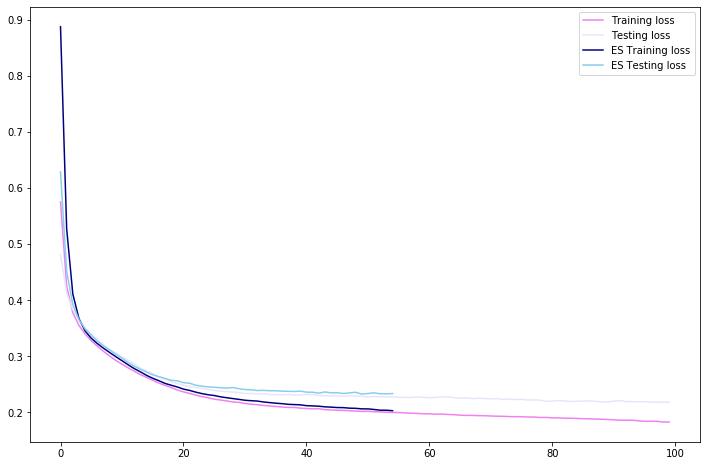

In [20]:
train_loss_es = history_es.history['loss']
test_loss_es = history_es.history['val_loss']
plt.figure(figsize=(12, 8))
plt.plot(train_loss, label='Training loss', color='violet')
plt.plot(test_loss, label='Testing loss', color='lavender')
plt.plot(train_loss_es, label='ES Training loss', color='navy')
plt.plot(test_loss_es, label='ES Testing loss', color='skyblue')
plt.legend();

In [21]:
history_es.history['acc'][-1], history_es.history['val_acc'][-1]

(0.93757504, 0.911271)

## Keras Resources
- [Keras EarlyStopping Documentation](https://keras.io/callbacks/#earlystopping)
- [Keras EarlyStopping Example](http://parneetk.github.io/blog/neural-networks-in-keras/)

## Tensorflow Resources
- [Tensorflow.Keras.callbacks.EarlyStopping Documentation](https://www.tensorflow.org/api_docs/python/tf/keras/callbacks/EarlyStopping)

# Optimization
---
Now we're going to talk about ways to speed up the process of optimization. Surprisingly, local optima are not often problems with neural networks; there's a much larger issue with "plateaus," or areas where the derivative is approximately 0. This makes learning much slower.

## Quick Fixes:
1. **Feature Scaling:** As we've discussed before, feature scaling can speed up the process of gradient descent. Because gradient descent works "geometrically," the scales of our $w$ values have a large impact on how quickly our parameters converge to the true value. Since we're working with many parameters (often 1,000 or more), scaling our features will speed up optimization.

2. **Mini-batch Gradient Descent:** In `sklearn`, we use `.fit()` to estimate the parameters in our model. We do the same in neural networks, but if we're working with a very large data set (as is common in neural networks), passing data through our network will cause learning to be slow. By specifying a `batch_size` within the `.fit()` method, we can expedite our learning.
    - `batch_size`: Integer or `None`. Number of samples per gradient update. If unspecified, it will default to 32.
    
**Note:** Mini batches will usually be a power of 2 (32, 64, 128, 256, 512) due to the fact that computers operate in base 2.

- [Overview of the three types of gradient descent: batch, stochastic, mini-batch](https://machinelearningmastery.com/gentle-introduction-mini-batch-gradient-descent-configure-batch-size/)

<a id='momentum'></a>
## Gradient Descent with Momentum

One problem we notice with mini-batch gradient descent compared to batch gradient descent is that it tends to oscillate more, due to the fact that at each iteration it is being fed less training data than batch gradient descent.

![](./assets/grad-descent.png)
![](./assets/mini-grad-descent.png)

*[source](http://pengcheng.tech/2017/09/28/gradient-descent-momentum-and-adam/)*

Ideally, we'd like to take advantage of the speed and memory efficiency of mini-batch gradient descent, without the oscillations. We can use the idea of **momentum** to help us out here. (Momentum is based on [exponentially weighted moving averages](https://www.compose.com/articles/metrics-maven-calculating-an-exponentially-weighted-moving-average-in-postgresql/), which causes our oscillations to largely cancel each other out.) 

Typically, when updating our parameters, we'll follow this formula:

$$W = W -\alpha\frac{\partial \text{loss}}{\partial W}$$  
$$b = b - \alpha\frac{\partial \text{loss}}{\partial b}$$

We're going to modify this formula to this form:

$$W = W -\alpha V_{\partial W}$$  
$$b = b - \alpha V_{\partial b}$$

Where 
$$V_{\partial W} = \beta V_{\partial W - 1} + (1-\beta)\frac{\partial \text{loss}}{\partial W}$$
and
$$V_{\partial b} = \beta V_{\partial b - 1} + (1-\beta)\frac{\partial \text{loss}}{\partial b}$$

When implementing gradient descent with momentum, you'll have two hyperparameters, $\alpha$ and $\beta$. From a practical point of view, $\beta$ is typically $0.9$, but you can test out other values if you'd like.

### ADAM Optimization

The optimization algorithm you'll likely use when implementing your feed-forward neural network is called ADAM (Adaptive Moment Estimation). It is a combination of gradient descent with momentum and another optimization method called RMSProp (Root Mean Square Propagation). For the sake of this lesson, we won't cover how ADAM works, but with gradient descent with momentum as building block, the ADAM optimization is not too far off, as it largely relies on the concept of momentum.

### Data Augmentation

One method of minimizing the risk of overfitting is to gather more data. While this is usually very costly, we may sometimes be able to take our existing data to generate substantially more data.
- Images: Reflect, crop, random rotations or distortions, adjust lighting.
    - [The Effectiveness of Data Augmentation in Image Classification using Deep Learning](http://cs231n.stanford.edu/reports/2017/pdfs/300.pdf)
- Non-Images: SMOTE (Synthetic Minority Over-Sampling Technique)
    - [SMOTE Paper](http://www.jair.org/media/953/live-953-2037-jair.pdf)

<a id='conclusion'></a>
# Conclusion

Today, we learned about three different methods of regularizing our neural networks: Regularization, dropout, and early stopping.

## Machine Learning Workflow

As promised, managing bias and variance takes a lot of our attention. If our bias or variance are high, it's likely that our model isn't performing as well as it could.

A workflow for how you should address this (in the context of neural networks and beyond) is as follows:

- Do we have high bias? (i.e. are we performing poorly on our training set?)
    - If so:
        - let's build a more complex model / bigger network!
        - let's consider a new architecture for our neural network!
        - let's train longer!
- Do we have high variance? (i.e. are we performing poorly on our test/holdout set?)
    - If so:
        - let's gather more data!
            - Usually very difficult, but we should use "data augmentation" if we can!
        - let's build a simpler model / smaller network!
        - let's consider a new architecture for our neural network!
        - let's regularize!
    - Once we're satisfied, return to the bias question and repeat.
    
**Note:** Before deep learning, most tools for handling high bias or high variance adversely affected the other. However, depending on the amount of data we have and how complex our network is, it's often the case that we can drastically reduce variance with out affecting bias.

We also learned about Mini-batch Gradient Descent and Gradient Descent with Momentum. You will almost always work with mini batches. And when optimizing, you will generally use a method called Adam Optimization that is built on a combination of Gradient Descent with Momentum and another optimization technique called RMSProp.

We also briefly discussed data augmentation as a method for increasing our sample sie.

<a id='references'></a>
## References and Resources:

- [DeepLearning.ai](https://www.deeplearning.ai/), Andrew Ng's Coursera course on Deep Learning
  - The videos from this course are on a [YouTube Channel](https://www.youtube.com/channel/UCcIXc5mJsHVYTZR1maL5l9w/featured)   
<br>
- [Deep Learning Book](http://www.deeplearningbook.org/), textbook written by Ian Goodfellow, creator of Generative Adversarial Networks (GANs)